# 03 - Моделирование




# 0. Импорты

In [ ]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.model_selection import KFold, cross_validate, train_test_split, GridSearchCV, cross_val_predict
from sklearn.preprocessing import FunctionTransformer, StandardScaler
from sklearn.dummy import DummyRegressor
from sklearn.pipeline import Pipeline
from sklearn.base import clone
import optuna
import json


PROJECT_ROOT = Path("..").resolve()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
    
# Подключение к файлам optuna
OPTUNA_DIR = PROJECT_ROOT / "notebooks" / "experiment_optuna"
OPTUNA_DIR.mkdir(parents=True, exist_ok=True)

from src.features import build_preprocessor
from src.model import get_linear_model_specs, get_tree_model_specs, get_boosting_model_specs, get_stacking_model_specs, get_neural_model_specs
from src.tuning import objective, objective_mlp_architecture


from src.validation import (
    CV_FOLDS,
    HOLDOUT_SIZE,
    RANDOM_STATE,
    cross_validate_regressor,
    evaluate_oof_ensembles,
    generate_oof_predictions,
    make_cv,
    residual_correlation,
    split_development_holdout,
)

sns.set_theme(style="whitegrid")
RAW_DIR = PROJECT_ROOT / "data" / "raw"
REPORTS_DIR = PROJECT_ROOT / "reports"
REPORTS_DIR.mkdir(exist_ok=True)

train = pd.read_csv(RAW_DIR / "train.csv")
test = pd.read_csv(RAW_DIR / "test.csv")

X = train.drop(columns="SalePrice")
y_log = np.log1p(train["SalePrice"])

print("RANDOM_STATE:", RANDOM_STATE)
print("HOLDOUT_SIZE:", HOLDOUT_SIZE)
print("CV_FOLDS:", CV_FOLDS)

RANDOM_STATE: 42
HOLDOUT_SIZE: 0.2
CV_FOLDS: 5


# 1. Фиксируем распредление

In [13]:
X_train, X_val, y_train, y_val = train_test_split(
    X,
    y_log,
    test_size=0.2,
    random_state=42
)
assert len(X_train) == 1168
assert len(X_val) == 292


,Development,Holdout
Количество,1168.00,292.00
Средняя цена,181441.54,178839.81
Медианная цена,165000.00,154150.00
Минимум,34900.00,35311.00
Максимум,745000.00,755000.00
Средний log1p,12.03,12.00
Std log1p,0.39,0.43


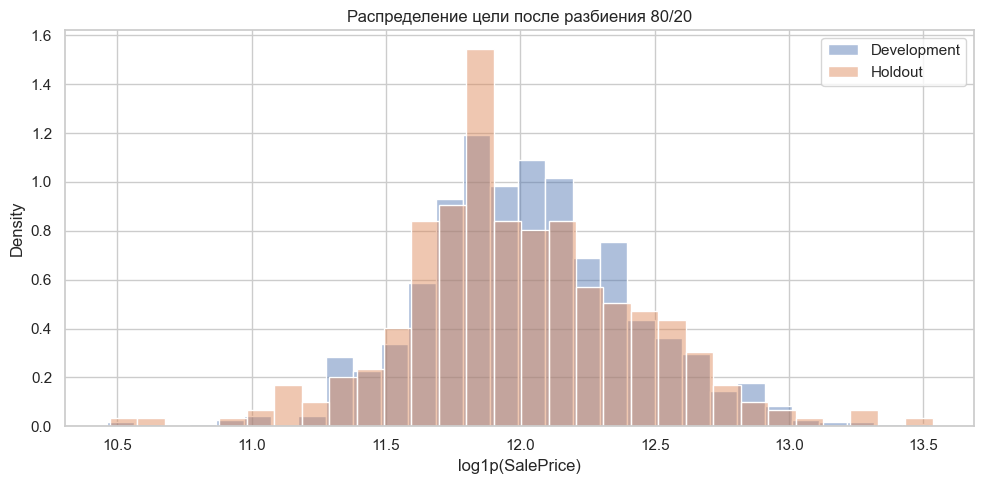

In [14]:
def price_summary(target_log):
    prices = np.expm1(target_log)
    return pd.Series(
        {
            "Количество": len(prices),
            "Средняя цена": prices.mean(),
            "Медианная цена": prices.median(),
            "Минимум": prices.min(),
            "Максимум": prices.max(),
            "Средний log1p": target_log.mean(),
            "Std log1p": target_log.std(),
        }
    )


distribution_summary = pd.DataFrame(
    {
        "Development": price_summary(y_train),
        "Holdout": price_summary(y_val),
    }
)
display(distribution_summary.round(2))

plt.figure(figsize=(10, 5))
sns.histplot(y_train, bins=30, stat="density", alpha=0.45, label="Development")
sns.histplot(y_val, bins=30, stat="density", alpha=0.45, label="Holdout")
plt.xlabel("log1p(SalePrice)")
plt.title("Распределение цели после разбиения 80/20")
plt.legend()
plt.tight_layout()
plt.show()

# 1.2 Настройка кросс валидации

In [15]:
cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# 2. Проверяем схему на DummyRegressor

In [ ]:
# Создаём Pipeline
# *Pipeline без preproccesing потому что DummyRegressor простой baseline
pipeline = Pipeline([
    ("model", DummyRegressor(strategy="mean"))
])

# Настраиваем Cross-Validation
cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Проводим Cross-Validation
scores = cross_val_score(
    pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring="neg_root_mean_squared_error"
)

print("RMSE по фолдам:", -scores)
print("Средний RMSE:", -scores.mean())
print("Стандартное отклонение:", scores.std())

RMSE по фолдам: [0.40608999 0.39624028 0.41064599 0.37232568 0.36505277]
Средний RMSE: 0.3900709431140048
Стандартное отклонение: 0.018214318890015208


# 3. Сравнение моделей

## 3.1 Классические линейные модели

In [17]:
model_specs = get_linear_model_specs()
results = []

for name, spec in model_specs.items():

    pipeline = Pipeline(
        steps=[
            (
                "preprocessing",
                build_preprocessor(
                    X_train,
                    scale_numeric=spec.scale_numeric
                )
            ),
            ("model", clone(spec.estimator))
        ]
    )

    scores = cross_validate(
        pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring={
            "rmse": "neg_root_mean_squared_error",
            "r2": "r2"
        },
        n_jobs=-1
    )

    results.append({
        "model": name,
        "RMSE_mean": -scores["test_rmse"].mean(),
        "RMSE_std": scores["test_rmse"].std(),
        "R2_mean": scores["test_r2"].mean()
    })

results_df = pd.DataFrame(results)

results_df = results_df.sort_values("RMSE_mean")

display(results_df)


,model,RMSE_mean,RMSE_std,R2_mean
1,ridge,0.148719,0.026961,0.852340
0,linear_regression,0.169702,0.026245,0.805886
2,lasso,0.390071,0.018214,-0.001276
3,elastic_net,0.390071,0.018214,-0.001276


In [18]:
param_grids = {
    "linear_regression": {},

    "ridge": {
        "model__alpha": np.logspace(-3, 3, 13)
    },

    "lasso": {
        "model__alpha": np.logspace(-5, 0, 11)
    },

    "elastic_net": {
        "model__alpha": np.logspace(-5, 0, 11),
        "model__l1_ratio": [0.1, 0.3, 0.5, 0.7, 0.9, 1.0]
    }
}

grid_results = []
best_models = {}

for name, spec in model_specs.items():

    pipeline = Pipeline([
        (
            "preprocessing",
            build_preprocessor(
                X_train,
                scale_numeric=spec.scale_numeric
            )
        ),
        ("model", clone(spec.estimator))
    ])

    grid_search = GridSearchCV(
        estimator=pipeline,
        param_grid=param_grids[name],
        scoring="neg_root_mean_squared_error",
        cv=cv,
        n_jobs=-1,
        refit=True
    )

    grid_search.fit(X_train, y_train)

    grid_results.append({
        "model": name,
        "best_RMSE": -grid_search.best_score_,
        "best_params": grid_search.best_params_
    })

    best_models[name] = grid_search.best_estimator_

results_grid_df = pd.DataFrame(grid_results)
results_grid_df = results_grid_df.sort_values("best_RMSE")

display(results_grid_df)

,model,best_RMSE,best_params
3,elastic_net,0.138438,"{'model__alpha': 0.001, 'model__l1_ratio': 0.7}"
2,lasso,0.138850,{'model__alpha': 0.001}
1,ridge,0.140187,{'model__alpha': 31.622776601683793}
0,linear_regression,0.169702,{}


### Выводы по линейным моделям

Были протестированы четыре модели: LinearRegression, Ridge, Lasso и ElasticNet. Для оценки качества использовалась 5-Fold Cross-Validation, а для подбора гиперпараметров — GridSearchCV.

| Модель | RMSE до | RMSE после |
|---|---:|---:|
| ElasticNet | 0.3901 | **0.1384** |
| Lasso | 0.3901 | 0.1389 |
| Ridge | 0.1487 | 0.1402 |
| LinearRegression | 0.1697 | 0.1697 |

**Основные наблюдения:**

- **ElasticNet** показал лучший результат при `alpha=0.001` и `l1_ratio=0.7`.
- **Lasso** практически не уступает ElasticNet. Разница в RMSE минимальна.
- **Ridge** также показал хорошее качество при `alpha≈31.62`.
- **LinearRegression** без регуляризации уступила всем трём регуляризованным моделям.
- Первоначальные результаты Lasso и ElasticNet были плохими из-за слишком сильной регуляризации (`alpha=1.0`). После подбора параметров RMSE значительно снизился.

Таким образом, регуляризация положительно повлияла на качество моделей. Лучший результат на кросс-валидации показал **ElasticNet (RMSE = 0.1384)**, однако Lasso и Ridge имеют сопоставимые результаты.


## 3.2 Деревья и ансамбли (без бустингов)

In [19]:
tree_specs = get_tree_model_specs()

tree_results = []

for name, spec in tree_specs.items():

    pipeline = Pipeline([
        (
            "preprocessing",
            build_preprocessor(
                X_train,
                scale_numeric=spec.scale_numeric
            )
        ),
        ("model", clone(spec.estimator))
    ])

    scores = cross_validate(
        pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring={
            "rmse": "neg_root_mean_squared_error",
            "r2": "r2"
        },
        return_train_score=True,
        n_jobs=-1
    )

    tree_results.append({
        "model": name,
        "Train_RMSE": -scores["train_rmse"].mean(),
        "CV_RMSE": -scores["test_rmse"].mean(),
        "CV_RMSE_std": scores["test_rmse"].std(),
        "CV_R2": scores["test_r2"].mean()
    })

tree_results_df = pd.DataFrame(tree_results)

display(tree_results_df.sort_values("CV_RMSE"))

,model,Train_RMSE,CV_RMSE,CV_RMSE_std,CV_R2
1,random_forest,5.488199e-02,0.147329,0.016319,0.857122
2,extra_trees,2.685435e-14,0.148413,0.011056,0.855048
0,decision_tree,-0.000000e+00,0.210134,0.017491,0.707946


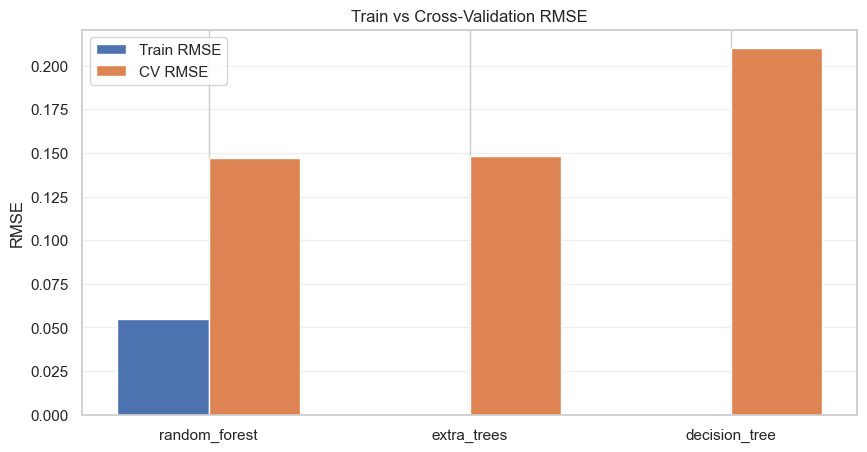

In [20]:
import matplotlib.pyplot as plt
import numpy as np

df = tree_results_df.sort_values("CV_RMSE")

x = np.arange(len(df))
width = 0.35

plt.figure(figsize=(10, 5))

plt.bar(x - width / 2, df["Train_RMSE"], width, label="Train RMSE")
plt.bar(x + width / 2, df["CV_RMSE"], width, label="CV RMSE")

plt.xticks(x, df["model"])
plt.ylabel("RMSE")
plt.title("Train vs Cross-Validation RMSE")
plt.legend()
plt.grid(axis="y", alpha=0.3)

plt.show()

### Подбираем гиперпараметры

In [21]:
tree_grid_results = []
best_tree_models = {}

tree_param_grids = {
    "decision_tree": {
        "model__max_depth": [3, 5, 10, 15, 20, None],
        "model__min_samples_split": [2, 5, 10],
        "model__min_samples_leaf": [1, 2, 5, 10]
    },

    "random_forest": {
        "model__max_depth": [10, 20, None],
        "model__min_samples_leaf": [1, 2, 5],
        "model__max_features": [0.5, 0.8, 1.0]
    },

    "extra_trees": {
        "model__max_depth": [10, 20, None],
        "model__min_samples_leaf": [1, 2, 5],
        "model__max_features": [0.5, 0.8, 1.0]
    }
}

for name, spec in tree_specs.items():

    print(f"Подбираем параметры: {name}")

    pipeline = Pipeline([
        (
            "preprocessing",
            build_preprocessor(
                X_train,
                scale_numeric=spec.scale_numeric
            )
        ),
        ("model", clone(spec.estimator))
    ])

    grid_search = GridSearchCV(
        estimator=pipeline,
        param_grid=tree_param_grids[name],
        scoring="neg_root_mean_squared_error",
        cv=cv,
        n_jobs=-1,
        refit=True,
        return_train_score=True
    )

    grid_search.fit(X_train, y_train)

    best_idx = grid_search.best_index_

    tree_grid_results.append({
        "model": name,
        "Train_RMSE": -grid_search.cv_results_[
            "mean_train_score"
        ][best_idx],
        "CV_RMSE": -grid_search.best_score_,
        "CV_RMSE_std": grid_search.cv_results_[
            "std_test_score"
        ][best_idx],
        "best_params": grid_search.best_params_
    })

    best_tree_models[name] = grid_search.best_estimator_

tree_grid_df = pd.DataFrame(tree_grid_results)

display(tree_grid_df.sort_values("CV_RMSE"))

Подбираем параметры: decision_tree
Подбираем параметры: random_forest
Подбираем параметры: extra_trees


,model,Train_RMSE,CV_RMSE,CV_RMSE_std,best_params
1,random_forest,0.053001,0.140316,0.014435,"{'model__max_depth': 20, 'model__max_features'..."
2,extra_trees,0.030182,0.145110,0.011513,"{'model__max_depth': None, 'model__max_feature..."
0,decision_tree,0.129963,0.191092,0.010188,"{'model__max_depth': 10, 'model__min_samples_l..."


### Выводы по деревьям решений и ансамблям

Были протестированы три модели: **DecisionTreeRegressor, RandomForestRegressor и ExtraTreesRegressor**. Для оценки качества использовалась 5-Fold Cross-Validation, а для подбора гиперпараметров — GridSearchCV.

| Модель | Train RMSE | CV RMSE |
|---|---:|---:|
| RandomForest | 0.0530 | **0.1403** |
| ExtraTrees | 0.0302 | 0.1451 |
| DecisionTree | 0.1300 | 0.1911 |

**Основные наблюдения:**

- **RandomForest** показал лучший результат среди рассмотренных моделей (CV RMSE = 0.1403).
- **ExtraTrees** немного уступил RandomForest на кросс-валидации, несмотря на более низкую ошибку на обучающей выборке.
- **DecisionTree** показал худший результат (CV RMSE = 0.1911). Одно дерево обладает высокой чувствительностью к особенностям обучающих данных и обычно хуже обобщает результаты по сравнению с ансамблями.
- **У RandomForest и ExtraTrees наблюдается большой разрыв между Train RMSE и CV RMSE**, что указывает на выраженное переобучение относительно обучающих данных.
- **Ансамбли деревьев работают лучше одиночного дерева**, поскольку объединение предсказаний нескольких моделей помогает снизить дисперсию и повысить устойчивость прогнозов.
- При сравнении с линейными моделями **ElasticNet (CV RMSE = 0.1384) немного превосходит RandomForest (0.1403)**, несмотря на меньшую сложность алгоритма.

Таким образом, применение ансамблей деревьев позволило существенно улучшить качество относительно одиночного DecisionTree. Лучший результат среди древесных моделей показал **RandomForest (RMSE = 0.1403)**.



## 3.3 Градиентные бустинги

Осуществим подбор гиперпараметров по Optuna

In [117]:
studies = {}
optuna_results = []
boosting_specs =  get_boosting_model_specs()

for name, spec in boosting_specs.items():

    print(f"\nОптимизация: {name}")

    study = optuna.create_study(
        direction="minimize",
        sampler=optuna.samplers.TPESampler(seed=42)
    )

    study.optimize(
    lambda trial: objective(
        trial,
        name,
        spec,
        X_train,
        y_train,
        cv
    ),
    n_trials=100,
    show_progress_bar=True
)

    studies[name] = study

    optuna_results.append({
        "model": name,
        "CV_RMSE": study.best_value,
        "best_params": study.best_params
    })

optuna_results_df = pd.DataFrame(optuna_results)

display(optuna_results_df.sort_values("CV_RMSE"))

[I 2026-10-12 21:16:00,606] A new study created in memory with name: no-name-8e700329-106d-4f88-ac46-3c7fa7a9a975



Оптимизация: adaboost


  0%|          | 0/100 [00:00<?, ?it/s]

[I 2026-10-12 21:16:12,549] Trial 0 finished with value: 0.17516838130431928 and parameters: {'n_estimators': 200, 'learning_rate': 0.7969454818643931, 'loss': 'linear'}. Best is trial 0 with value: 0.17516838130431928.
[I 2026-10-12 21:16:15,510] Trial 1 finished with value: 0.20119352497226925 and parameters: {'n_estimators': 100, 'learning_rate': 0.01306673923805328, 'loss': 'linear'}. Best is trial 0 with value: 0.17516838130431928.
[I 2026-10-12 21:16:17,523] Trial 2 finished with value: 0.1800831195820238 and parameters: {'n_estimators': 50, 'learning_rate': 0.8706020878304853, 'loss': 'linear'}. Best is trial 0 with value: 0.17516838130431928.
[I 2026-10-12 21:16:18,813] Trial 3 finished with value: 0.19249891212024134 and parameters: {'n_estimators': 100, 'learning_rate': 0.04059611610484305, 'loss': 'linear'}. Best is trial 0 with value: 0.17516838130431928.
[I 2026-10-12 21:16:22,336] Trial 4 finished with value: 0.1883890175773113 and parameters: {'n_estimators': 350, 'learn

[I 2026-10-12 21:20:16,388] A new study created in memory with name: no-name-ea72b125-3e0b-441e-affb-f9b3e1df11f8


...

[I 2026-10-12 21:41:13,777] A new study created in memory with name: no-name-645d8ad2-b390-4273-a8d6-c204066651f1


[I 2026-10-12 21:41:13,777] Trial 99 finished with value: 0.12321735786702817 and parameters: {'n_estimators': 400, 'learning_rate': 0.051485372280176474, 'num_leaves': 7, 'max_depth': 12, 'min_child_samples': 8, 'subsample': 0.6213331189038942, 'subsample_freq': 1, 'colsample_bytree': 0.9376568462568007, 'reg_lambda': 6.482689604929248}. Best is trial 77 with value: 0.12065246161396208.

Оптимизация: catboost


  0%|          | 0/100 [00:00<?, ?it/s]

[I 2026-10-12 21:41:23,905] Trial 0 finished with value: 0.12741240172045418 and parameters: {'iterations': 400, 'learning_rate': 0.17254716573280354, 'depth': 7, 'l2_leaf_reg': 6.009974718380312, 'random_strength': 0.02636875533972305}. Best is trial 0 with value: 0.12741240172045418.
[I 2026-10-12 21:41:36,054] Trial 1 finished with value: 0.15297034011092273 and parameters: {'iterations': 300, 'learning_rate': 0.011900590783184251, 'depth': 8, 'l2_leaf_reg': 6.054365855469246, 'random_strength': 0.8148293210105289}. Best is trial 0 with value: 0.12741240172045418.
[I 2026-10-12 21:41:41,352] Trial 2 finished with value: 0.12646677372053938 and parameters: {'iterations': 200, 'learning_rate': 0.18276027831785724, 'depth': 7, 'l2_leaf_reg': 1.8891200276189386, 'random_strength': 0.030955664602423716}. Best is trial 2 with value: 0.12646677372053938.
[I 2026-10-12 21:41:45,316] Trial 3 finished with value: 0.13052503693831813 and parameters: {'iterations': 300, 'learning_rate': 0.02487

,model,CV_RMSE,best_params
5,catboost,0.116511,"{'iterations': 800, 'learning_rate': 0.0303783..."
1,gradient_boosting,0.120066,"{'n_estimators': 600, 'learning_rate': 0.04380..."
4,lightgbm,0.120652,"{'n_estimators': 400, 'learning_rate': 0.07134..."
3,xgboost,0.122044,"{'n_estimators': 700, 'learning_rate': 0.05626..."
2,hist_gradient_boosting,0.124436,"{'max_iter': 600, 'learning_rate': 0.039239295..."
0,adaboost,0.172673,"{'n_estimators': 100, 'learning_rate': 0.68426..."


###  Сохраняем лучшие гиперпараметры бустингов

In [ ]:
REPORTS_DIR.mkdir(parents=True, exist_ok=True)

# Сохраняем таблицу результатов
optuna_results_df.to_csv(
    REPORTS_DIR / "boosting_optuna_results.csv",
    index=False
)

# Сохраняем лучшие параметры
boosting_params = {
    name: study.best_params
    for name, study in studies.items()
}

with open(
    REPORTS_DIR / "boosting_best_params.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(boosting_params, f, indent=4)

print("Результаты бустингов сохранены")

Результаты бустингов сохранены


## 3.4 Стэкинг

In [119]:
stacking_specs = get_stacking_model_specs(X_train)

stacking_results = []

combinations = {
    "stacking_a": ["elastic_net", "lightgbm"],
    "stacking_b": ["lightgbm", "catboost"],
    "stacking_c": ["elastic_net", "lightgbm", "catboost"],
    "stacking_d": [
        "elastic_net",
        "random_forest",
        "lightgbm",
        "catboost"
    ],
    "stacking_xce": ["xgboost", "catboost", "elastic_net"]
}

stacking_specs = get_stacking_model_specs(
    X_train,
    combinations=combinations
)

for name, spec in stacking_specs.items():

    print(f"Обучаем {name}")

    scores = cross_validate(
        clone(spec.estimator),
        X_train,
        y_train,
        cv=cv,
        scoring={
            "rmse": "neg_root_mean_squared_error",
            "r2": "r2"
        },
        return_train_score=True,
        n_jobs=1,
        error_score="raise"
    )

    stacking_results.append({
        "model": name,
        "Train_RMSE": -scores["train_rmse"].mean(),
        "CV_RMSE": -scores["test_rmse"].mean(),
        "CV_RMSE_std": scores["test_rmse"].std(),
        "CV_R2": scores["test_r2"].mean()
    })

stacking_results_df = pd.DataFrame(stacking_results)

display(stacking_results_df.sort_values("CV_RMSE"))

Обучаем stacking_a


c:\Users\Егор\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\impute\_base.py:572: FutureWarning:

Currently, when `keep_empty_feature=False` and `strategy="constant"`, empty features are not dropped. This behaviour will change in version 1.8. Set `keep_empty_feature=True` to preserve this behaviour.

c:\Users\Егор\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\impute\_base.py:572: FutureWarning:

Currently, when `keep_empty_feature=False` and `strategy="constant"`, empty features are not dropped. This behaviour will change in version 1.8. Set `keep_empty_feature=True` to preserve this behaviour.



Обучаем stacking_b


c:\Users\Егор\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\impute\_base.py:572: FutureWarning:

Currently, when `keep_empty_feature=False` and `strategy="constant"`, empty features are not dropped. This behaviour will change in version 1.8. Set `keep_empty_feature=True` to preserve this behaviour.

c:\Users\Егор\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\impute\_base.py:572: FutureWarning:

Currently, when `keep_empty_feature=False` and `strategy="constant"`, empty features are not dropped. This behaviour will change in version 1.8. Set `keep_empty_feature=True` to preserve this behaviour.



Обучаем stacking_c


...

Обучаем stacking_d


c:\Users\Егор\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\impute\_base.py:572: FutureWarning:

Currently, when `keep_empty_feature=False` and `strategy="constant"`, empty features are not dropped. This behaviour will change in version 1.8. Set `keep_empty_feature=True` to preserve this behaviour.

c:\Users\Егор\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\impute\_base.py:572: FutureWarning:

Currently, when `keep_empty_feature=False` and `strategy="constant"`, empty features are not dropped. This behaviour will change in version 1.8. Set `keep_empty_feature=True` to preserve this behaviour.

c:\Users\Егор\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\impute\_base.py:572: FutureWarning:

Currently, when `keep_empty_feature=False` and `strategy="constant"`, empty features are not dropped. This behaviour will change in version 1.8. Set `keep_empty_feature=True` to preserve this behaviour.

c:\Users\Егор\AppData\Local\Programs\

Обучаем stacking_xce


c:\Users\Егор\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\impute\_base.py:572: FutureWarning:

Currently, when `keep_empty_feature=False` and `strategy="constant"`, empty features are not dropped. This behaviour will change in version 1.8. Set `keep_empty_feature=True` to preserve this behaviour.

c:\Users\Егор\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\impute\_base.py:572: FutureWarning:

Currently, when `keep_empty_feature=False` and `strategy="constant"`, empty features are not dropped. This behaviour will change in version 1.8. Set `keep_empty_feature=True` to preserve this behaviour.

c:\Users\Егор\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\impute\_base.py:572: FutureWarning:

Currently, when `keep_empty_feature=False` and `strategy="constant"`, empty features are not dropped. This behaviour will change in version 1.8. Set `keep_empty_feature=True` to preserve this behaviour.



,model,Train_RMSE,CV_RMSE,CV_RMSE_std,CV_R2
3,stacking_d,0.057833,0.121335,0.016551,0.903026
1,stacking_b,0.057315,0.121520,0.016556,0.902732
2,stacking_c,0.057315,0.121520,0.016556,0.902732
4,stacking_xce,0.061091,0.122274,0.016271,0.901540
0,stacking_a,0.045058,0.129482,0.016704,0.889592


In [ ]:
REPORTS_DIR = PROJECT_ROOT / "reports"
REPORTS_DIR.mkdir(parents=True, exist_ok=True)

# 1. Сохраняем CV-результаты всех стекингов
stacking_results_df.to_csv(
    REPORTS_DIR / "stacking_cv_results.csv",
    index=False
)

# 2. Находим лучший стекинг по CV RMSE
best_name = stacking_results_df.loc[
    stacking_results_df["CV_RMSE"].idxmin(),
    "model"
]

best_spec = stacking_specs[best_name]
best_model = best_spec.estimator

# 3. Сохраняем конфигурацию лучшего стекинга
stacking_config = {
    "model": best_name,
    "CV_RMSE": float(
        stacking_results_df.loc[
            stacking_results_df["model"] == best_name,
            "CV_RMSE"
        ].iloc[0]
    ),
    "base_models": combinations[best_name],
    "base_estimators": {
        name: {
            "class": type(estimator).__name__,
            "params": estimator.get_params(deep=False)
        }
        for name, estimator in best_model.estimators
    },
    "final_estimator": {
        "class": type(best_model.final_estimator).__name__,
        "params": best_model.final_estimator.get_params(deep=False)
    },
    "stacking_cv": best_model.cv,
    "passthrough": best_model.passthrough
}

with open(
    REPORTS_DIR / "stacking_best_params.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(
        stacking_config,
        f,
        indent=4,
        ensure_ascii=False,
        default=str
    )

print(f"Лучший стекинг: {best_name}")
print(f"CV RMSE: {stacking_config['CV_RMSE']:.6f}")
print("Результаты сохранены в reports/")

Лучший стекинг: stacking_d
CV RMSE: 0.121335
Результаты сохранены в reports/


1. CatBoost и LightGBM вносят основной вклад.
Метамодель использует преимущественно их предсказания для формирования итогового прогноза.

### Подбираем гиперпараметры для стэкинга

In [ ]:
combinations = {
    "stacking_d": [
        "elastic_net",
        "random_forest",
        "lightgbm",
        "catboost"
    ]
}

stacking_specs = get_stacking_model_specs(
    X_train,
    combinations=combinations
)

stacking_d_spec = stacking_specs["stacking_d"]

In [ ]:
study_stacking = optuna.create_study(
    study_name="house_prices_stacking_d",
    direction="minimize",
    storage=f"sqlite:///{(OPTUNA_DIR / 'optuna_mlp.db').as_posix()}",
    load_if_exists=True,
    sampler=optuna.samplers.TPESampler(seed=42)
)

study_stacking.optimize(
    lambda trial: objective_stacking(
        trial,
        stacking_d_spec,
        X_train,
        y_train,
        cv
    ),
    n_trials=30,
    show_progress_bar=True
)

print("Best RMSE:", study_stacking.best_value)
print("Best params:", study_stacking.best_params)

[I 2026-10-12 00:52:01,456] A new study created in RDB with name: house_prices_stacking_d


  0%|          | 0/30 [00:00<?, ?it/s]

c:\Users\Егор\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\impute\_base.py:572: FutureWarning: Currently, when `keep_empty_feature=False` and `strategy="constant"`, empty features are not dropped. This behaviour will change in version 1.8. Set `keep_empty_feature=True` to preserve this behaviour.
  warnings.warn(
c:\Users\Егор\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\impute\_base.py:572: FutureWarning: Currently, when `keep_empty_feature=False` and `strategy="constant"`, empty features are not dropped. This behaviour will change in version 1.8. Set `keep_empty_feature=True` to preserve this behaviour.
  warnings.warn(
c:\Users\Егор\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\impute\_base.py:572: FutureWarning: Currently, when `keep_empty_feature=False` and `strategy="constant"`, empty features are not dropped. This behaviour will change in version 1.8. Set `keep_empty_feature=True` to preserve this behaviour.
  warning

[I 2026-10-12 00:56:51,355] Trial 0 finished with value: 0.156582330418417 and parameters: {'meta_model': 'elastic_net', 'elastic_alpha': 0.0457056309980145, 'elastic_l1_ratio': 0.6387926357773329}. Best is trial 0 with value: 0.156582330418417.


c:\Users\Егор\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\impute\_base.py:572: FutureWarning: Currently, when `keep_empty_feature=False` and `strategy="constant"`, empty features are not dropped. This behaviour will change in version 1.8. Set `keep_empty_feature=True` to preserve this behaviour.
  warnings.warn(
c:\Users\Егор\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\impute\_base.py:572: FutureWarning: Currently, when `keep_empty_feature=False` and `strategy="constant"`, empty features are not dropped. This behaviour will change in version 1.8. Set `keep_empty_feature=True` to preserve this behaviour.
  warnings.warn(
c:\Users\Егор\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\impute\_base.py:572: FutureWarning: Currently, when `keep_empty_feature=False` and `strategy="constant"`, empty features are not dropped. This behaviour will change in version 1.8. Set `keep_empty_feature=True` to preserve this behaviour.
  warning

...

[I 2026-10-12 03:07:07,290] Trial 27 finished with value: 0.12400836399377431 and parameters: {'meta_model': 'ridge', 'ridge_alpha': 6.397394977955556}. Best is trial 25 with value: 0.12093375103004808.


c:\Users\Егор\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\impute\_base.py:572: FutureWarning: Currently, when `keep_empty_feature=False` and `strategy="constant"`, empty features are not dropped. This behaviour will change in version 1.8. Set `keep_empty_feature=True` to preserve this behaviour.
  warnings.warn(
c:\Users\Егор\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\impute\_base.py:572: FutureWarning: Currently, when `keep_empty_feature=False` and `strategy="constant"`, empty features are not dropped. This behaviour will change in version 1.8. Set `keep_empty_feature=True` to preserve this behaviour.
  warnings.warn(
c:\Users\Егор\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\impute\_base.py:572: FutureWarning: Currently, when `keep_empty_feature=False` and `strategy="constant"`, empty features are not dropped. This behaviour will change in version 1.8. Set `keep_empty_feature=True` to preserve this behaviour.
  warning

[I 2026-10-12 03:11:58,720] Trial 28 finished with value: 0.12093511282611298 and parameters: {'meta_model': 'ridge', 'ridge_alpha': 0.1817231236712672}. Best is trial 25 with value: 0.12093375103004808.


c:\Users\Егор\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\impute\_base.py:572: FutureWarning: Currently, when `keep_empty_feature=False` and `strategy="constant"`, empty features are not dropped. This behaviour will change in version 1.8. Set `keep_empty_feature=True` to preserve this behaviour.
  warnings.warn(
c:\Users\Егор\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\impute\_base.py:572: FutureWarning: Currently, when `keep_empty_feature=False` and `strategy="constant"`, empty features are not dropped. This behaviour will change in version 1.8. Set `keep_empty_feature=True` to preserve this behaviour.
  warnings.warn(
c:\Users\Егор\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\impute\_base.py:572: FutureWarning: Currently, when `keep_empty_feature=False` and `strategy="constant"`, empty features are not dropped. This behaviour will change in version 1.8. Set `keep_empty_feature=True` to preserve this behaviour.
  warning

[I 2026-10-12 03:16:47,744] Trial 29 finished with value: 0.12193178524738238 and parameters: {'meta_model': 'elastic_net', 'elastic_alpha': 0.004525016339582621, 'elastic_l1_ratio': 0.9475849245820684}. Best is trial 25 with value: 0.12093375103004808.
Best RMSE: 0.12093375103004808
Best params: {'meta_model': 'ridge', 'ridge_alpha': 0.12759923423230501}


## 3.5 Нейронные сети

In [92]:

neural_specs = get_neural_model_specs()

neural_results = []

for name, spec in neural_specs.items():

    pipeline = Pipeline([
        (
            "preprocessing",
            build_preprocessor(
                X_train,
                scale_numeric=spec.scale_numeric
            )
        ),
        (
            "_to_dense",
            FunctionTransformer(
                _to_dense,
                accept_sparse=True
            )
        ),
        ("model", clone(spec.estimator))
    ])

    scores = cross_validate(
        pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring={
            "rmse": "neg_root_mean_squared_error",
            "r2": "r2"
        },
        return_train_score=True,
        n_jobs=1,
        error_score="raise"
    )

    neural_results.append({
        "model": name,
        "Train_RMSE": -scores["train_rmse"].mean(),
        "CV_RMSE": -scores["test_rmse"].mean(),
        "CV_RMSE_std": scores["test_rmse"].std(),
        "CV_R2": scores["test_r2"].mean()
    })

neural_results_df = pd.DataFrame(neural_results)

display(neural_results_df.sort_values("CV_RMSE"))

,model,Train_RMSE,CV_RMSE,CV_RMSE_std,CV_R2
0,mlp,0.130933,0.327822,0.16845,0.161783


### Поиск аномалий

Запустим отдельно по фолдам в выведим метрики

In [93]:
scores = cross_validate(
    pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring={
        "rmse": "neg_root_mean_squared_error",
        "r2": "r2"
    },
    return_train_score=True,
    n_jobs=1
)

fold_results = pd.DataFrame({
    "Fold": range(1, 6),
    "Train_RMSE": -scores["train_rmse"],
    "CV_RMSE": -scores["test_rmse"],
    "CV_R2": scores["test_r2"]
})

display(fold_results)

,Fold,Train_RMSE,CV_RMSE,CV_R2
0,1,0.149354,0.551878,-0.847011
1,2,0.170540,0.195373,0.756207
2,3,0.154889,0.514691,-0.575010
3,4,0.085616,0.203378,0.701435
4,5,0.094264,0.173789,0.773296


Проблема сосредоточена в двух фолдах 1 и 3
Проверим, какие объекты дают наибольшую ошибку

In [ ]:
y_pred_oof = cross_val_predict(
    pipeline,
    X_train,
    y_train,
    cv=cv,
    n_jobs=1
)

errors_df = pd.DataFrame({
    "y_true": np.asarray(y_train),
    "y_pred": y_pred_oof
}, index=X_train.index)

errors_df["abs_error"] = abs(
    errors_df["y_true"] - errors_df["y_pred"]
)

display(
    errors_df.sort_values(
        "abs_error", ascending=False
    ).head(15)
)
# Добавляем номер CV-фолда для каждого объекта
fold_ids = np.zeros(len(X_train), dtype=int)

for fold, (_, val_idx) in enumerate(cv.split(X_train), start=1):
    fold_ids[val_idx] = fold

errors_df["fold"] = fold_ids

# Смотрим 15 самых больших ошибок
display(
    errors_df.sort_values(
        "abs_error", ascending=False
    ).head(15)
)

,y_true,y_pred,abs_error,fold
346,11.928348,19.646926,7.718579,1
1423,12.524421,16.516312,3.991891,3
810,12.106258,15.527018,3.420760,3
197,12.367345,15.702493,3.335148,3
1298,11.982935,15.261392,3.278457,3
1182,13.521141,15.333090,1.811949,3
523,12.126764,13.929260,1.802496,2
635,12.206078,13.458849,1.252771,4
313,12.834684,13.930328,1.095644,2
1230,12.154785,11.059500,1.095285,4


In [97]:
worst_ids = errors_df.nlargest(5, "abs_error").index

columns = [
    "OverallQual",
    "GrLivArea",
    "LotArea",
    "TotalBsmtSF",
    "GarageArea",
    "YearBuilt"
]

display(
    X_train.loc[worst_ids, columns]
)

,OverallQual,GrLivArea,LotArea,TotalBsmtSF,GarageArea,YearBuilt
346,6,958,12772,958,301,1960
1423,6,2201,19690,697,432,1966
810,6,1309,10140,1040,484,1974
197,8,3112,25419,1360,795,1918
1298,10,5642,63887,6110,1418,2008


In [ ]:
numeric_columns = X_train.select_dtypes(
    include=np.number
).columns

scaler = StandardScaler()

X_scaled = pd.DataFrame(
    scaler.fit_transform(X_train[numeric_columns]),
    columns=numeric_columns,
    index=X_train.index
)

worst_ids = errors_df.nlargest(5, "abs_error").index

for idx in worst_ids:
    print(f"\nОбъект {idx}")

    display(
        X_scaled.loc[idx]
        .abs()
        .sort_values(ascending=False)
        .head(10)
    )


Объект 346


MiscVal         27.946187
OverallCond      2.165000
BedroomAbvGr     1.106774
GrLivArea        1.086213
GarageCars       1.056544
FullBath         1.055566
TotRmsAbvGrd     0.964566
Fireplaces       0.958592
Id               0.902909
MoSold           0.882603
Name: 346, dtype: float64


Объект 1423


PoolArea        17.656322
WoodDeckSF       3.780387
OpenPorchSF      2.686036
Id               1.630095
BedroomAbvGr     1.379210
YrSold           1.375486
GrLivArea        1.284983
OverallCond      1.268609
1stFlrSF         1.049509
BsmtFinSF1       0.971996
Name: 1423, dtype: float64


Объект 810


PoolArea        15.494454
BsmtFinSF2       2.098312
MoSold           2.006382
YrSold           1.375486
WoodDeckSF       1.304116
BsmtUnfSF        1.278864
HalfBath         1.236947
BsmtFullBath     1.105320
FullBath         1.055566
TotRmsAbvGrd     0.964566
Name: 810, dtype: float64


Объект 197


PoolArea         12.227632
EnclosedPorch     8.543178
LowQualFinSF      8.070427
LotFrontage       4.165586
BsmtHalfBath      3.991043
GrLivArea         3.022842
GarageYrBlt       2.454195
2ndFlrSF          2.293329
YearBuilt         1.727387
GarageArea        1.510514
Name: 197, dtype: float64


Объект 1298


TotalBsmtSF    11.460545
PoolArea       11.458968
BsmtFinSF1     11.327666
LotFrontage     9.751521
1stFlrSF        9.113990
GrLivArea       7.849169
LotArea         4.946402
GarageArea      4.463051
MasVnrArea      4.002295
Fireplaces      3.693633
Name: 1298, dtype: float64

Здесь мы ограничиваем значения преобразованных признаков диапазоном от −5 до 5. Это диагностический эксперимент, а не окончательно выбранный препроцессинг: ограничение также затронет закодированные категориальные признаки, если их значения выходят за границы.

In [99]:

def clip_features(X):
    return np.clip(X, -5, 5)

mlp_clip = clone(pipeline)

mlp_clip.steps.insert(
    -1,
    ("clip", FunctionTransformer(clip_features))
)

scores = cross_validate(
    mlp_clip,
    X_train,
    y_train,
    cv=cv,
    scoring="neg_root_mean_squared_error",
    return_train_score=True,
    n_jobs=1
)

print("CV RMSE:", -scores["test_score"].mean())
print("RMSE по фолдам:", -scores["test_score"])

CV RMSE: 0.19535257442377074
RMSE по фолдам: [0.19261577 0.18264218 0.24262905 0.18680162 0.17207427]


Проверим разрыв Train и CV

In [100]:
print("Train RMSE:", -scores["train_score"].mean())
print("CV RMSE:", -scores["test_score"].mean())
print("Разрыв:", (
    -scores["test_score"].mean()
    + scores["train_score"].mean()
))

Train RMSE: 0.0902109949619109
CV RMSE: 0.19535257442377074
Разрыв: 0.10514157946185984


### Выводы по первому эксперименту с MLPRegressor

Первоначально нейросеть показала низкое качество: **CV RMSE = 0.3278** при Train RMSE = 0.1309.

Анализ ошибок показал, что основная проблема сосредоточена на двух валидационных фолдах, где модель допускала экстремально большие ошибки предсказания.

При исследовании проблемных объектов обнаружились признаки с аномально высокими Z-score, особенно `PoolArea`. Это позволило предположить, что нейросеть чувствительна к экстремальным значениям признаков даже после StandardScaler.

Для проверки гипотезы был применён **clipping признаков в диапазоне [-5, 5]**.

| Метрика | До clipping | После clipping |
|---|---:|---:|
| Train RMSE | 0.1309 | 0.0902 |
| CV RMSE | 0.3278 | 0.1954 |
| Разрыв Train/CV | 0.1969 | 0.1051 |

После clipping ошибка на кросс-валидации снизилась примерно на **40%**, а результаты между фолдами стали значительно стабильнее.

Однако разрыв между Train RMSE (0.0902) и CV RMSE (0.1954) остаётся существенным. Это указывает на сохраняющееся переобучение модели.

### Почему стоит попробовать более простую архитектуру?

Текущая нейросеть содержит два скрытых слоя по 128 и 64 нейрона. Для нашего небольшого датасета такая архитектура может обладать избыточной сложностью и подстраиваться под особенности обучающих объектов.

Поэтому следующим экспериментом будет **уменьшение количества нейронов до (32, 16)**, усиление L2-регуляризации и изменение параметров обучения.

Цель — проверить, сможет ли более простая нейросеть лучше обобщать данные, уменьшить разницу между Train и CV RMSE и повысить качество предсказаний на новых объектах.

### Проверим более простую архитектуру

In [101]:
mlp_simple = clone(mlp_clip)

mlp_simple.set_params(
    model__hidden_layer_sizes=(32, 16),
    model__alpha=0.01,
    model__learning_rate_init=0.0005,
    model__max_iter=1500,
    model__early_stopping=False
)

scores_simple = cross_validate(
    mlp_simple,
    X_train,
    y_train,
    cv=cv,
    scoring="neg_root_mean_squared_error",
    return_train_score=True,
    n_jobs=1
)

print("Train RMSE:", -scores_simple["train_score"].mean())
print("CV RMSE:", -scores_simple["test_score"].mean())
print("CV RMSE по фолдам:", -scores_simple["test_score"])

Train RMSE: 0.04897944854926066
CV RMSE: 0.16514461351493398
CV RMSE по фолдам: [0.15815219 0.17439957 0.17227596 0.15504026 0.16585509]


### Выбор оптимизатора

In [ ]:
study_mlp_optimizer = optuna.create_study(
    study_name="mlp_optimizer_search",
    direction="minimize",
    sampler=optuna.samplers.TPESampler(seed=42),
    storage=f"sqlite:///{(OPTUNA_DIR / 'optuna_mlp.db').as_posix()}",
    load_if_exists=True
)

study_mlp_optimizer.optimize(
    lambda trial: objective_mlp_optimizer(
        trial,
        mlp_clip,
        X_train,
        y_train,
        cv
    ),
    n_trials=60,
    show_progress_bar=True
)

print("Best CV RMSE:", study_mlp_optimizer.best_value)
print("Best params:", study_mlp_optimizer.best_params)

[I 2026-10-12 14:18:54,700] A new study created in RDB with name: mlp_optimizer_search


  0%|          | 0/60 [00:00<?, ?it/s]

[I 2026-10-12 14:19:05,562] Trial 0 finished with value: 0.23424507711905812 and parameters: {'solver': 'sgd', 'sgd_lr': 0.0015751320499779737, 'sgd_momentum': 0.5764491338167939, 'sgd_batch_size': 64}. Best is trial 0 with value: 0.23424507711905812.
[I 2026-10-12 14:19:48,694] Trial 1 finished with value: 0.1314016288592245 and parameters: {'solver': 'sgd', 'sgd_lr': 0.008706020878304856, 'sgd_momentum': 0.9078968939922066, 'sgd_batch_size': 16}. Best is trial 1 with value: 0.1314016288592245.
[I 2026-10-12 14:20:01,288] Trial 2 finished with value: 0.26179566037161534 and parameters: {'solver': 'sgd', 'sgd_lr': 0.0003823475224675188, 'sgd_momentum': 0.7998079184139659, 'sgd_batch_size': 64}. Best is trial 1 with value: 0.1314016288592245.
[I 2026-10-12 14:20:18,231] Trial 3 finished with value: 0.20992893554024983 and parameters: {'solver': 'sgd', 'sgd_lr': 0.0010677482709481358, 'sgd_momentum': 0.7902831387424007, 'sgd_batch_size': 32}. Best is trial 1 with value: 0.131401628859224

c:\Users\Егор\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:546: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  self.n_iter_ = _check_optimize_result("lbfgs", opt_res, self.max_iter)
c:\Users\Егор\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:546: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  self.n_iter_ = _check_optimize_result("lbfgs", opt_res, self.max_iter)
c:\Users\Егор\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.

[I 2026-10-12 14:20:54,988] Trial 4 finished with value: 0.20222102455669466 and parameters: {'solver': 'lbfgs'}. Best is trial 1 with value: 0.1314016288592245.
[I 2026-10-12 14:21:00,435] Trial 5 finished with value: 0.16116244788105488 and parameters: {'solver': 'adam', 'adam_lr': 0.0023359635026261607, 'adam_batch_size': 64}. Best is trial 1 with value: 0.1314016288592245.
[I 2026-10-12 14:21:17,764] Trial 6 finished with value: 0.20281995136772452 and parameters: {'solver': 'sgd', 'sgd_lr': 0.0021137059440645744, 'sgd_momentum': 0.6527384272838114, 'sgd_batch_size': 32}. Best is trial 1 with value: 0.1314016288592245.
[I 2026-10-12 14:21:22,112] Trial 7 finished with value: 0.1863194011822338 and parameters: {'solver': 'adam', 'adam_lr': 0.006161049539380964, 'adam_batch_size': 32}. Best is trial 1 with value: 0.1314016288592245.


...

[I 2026-10-12 14:37:36,325] Trial 39 finished with value: 0.20222102455669466 and parameters: {'solver': 'lbfgs'}. Best is trial 1 with value: 0.1314016288592245.
[I 2026-10-12 14:38:06,074] Trial 40 finished with value: 0.1647943135489512 and parameters: {'solver': 'adam', 'adam_lr': 0.00032094794147224817, 'adam_batch_size': 16}. Best is trial 1 with value: 0.1314016288592245.
[I 2026-10-12 14:38:34,420] Trial 41 finished with value: 0.1551918972900063 and parameters: {'solver': 'adam', 'adam_lr': 0.00010580716775792539, 'adam_batch_size': 16}. Best is trial 1 with value: 0.1314016288592245.
[I 2026-10-12 14:39:04,672] Trial 42 finished with value: 0.16016768534993947 and parameters: {'solver': 'adam', 'adam_lr': 0.00015587425419730407, 'adam_batch_size': 16}. Best is trial 1 with value: 0.1314016288592245.
[I 2026-10-12 14:39:39,485] Trial 43 finished with value: 0.1560292866479904 and parameters: {'solver': 'adam', 'adam_lr': 0.00010519670019102597, 'adam_batch_size': 16}. Best is 

c:\Users\Егор\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:546: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  self.n_iter_ = _check_optimize_result("lbfgs", opt_res, self.max_iter)
c:\Users\Егор\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:546: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  self.n_iter_ = _check_optimize_result("lbfgs", opt_res, self.max_iter)
c:\Users\Егор\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.

[I 2026-10-12 14:41:23,558] Trial 47 finished with value: 0.20222102455669466 and parameters: {'solver': 'lbfgs'}. Best is trial 1 with value: 0.1314016288592245.
[I 2026-10-12 14:41:44,004] Trial 48 finished with value: 0.15741494872674516 and parameters: {'solver': 'adam', 'adam_lr': 0.00034931888218124997, 'adam_batch_size': 32}. Best is trial 1 with value: 0.1314016288592245.
[I 2026-10-12 14:42:03,033] Trial 49 finished with value: 0.3337559352401384 and parameters: {'solver': 'sgd', 'sgd_lr': 0.00019184075394875193, 'sgd_momentum': 0.6032935884486439, 'sgd_batch_size': 64}. Best is trial 1 with value: 0.1314016288592245.
[I 2026-10-12 14:42:35,736] Trial 50 finished with value: 0.15942419467175137 and parameters: {'solver': 'adam', 'adam_lr': 0.0001998126651790456, 'adam_batch_size': 16}. Best is trial 1 with value: 0.1314016288592245.
[I 2026-10-12 14:43:08,543] Trial 51 finished with value: 0.15617837374423135 and parameters: {'solver': 'adam', 'adam_lr': 0.00010183547927097226

c:\Users\Егор\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:546: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  self.n_iter_ = _check_optimize_result("lbfgs", opt_res, self.max_iter)
c:\Users\Егор\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:546: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  self.n_iter_ = _check_optimize_result("lbfgs", opt_res, self.max_iter)
c:\Users\Егор\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.

[I 2026-10-12 14:45:22,590] Trial 57 finished with value: 0.20222102455669466 and parameters: {'solver': 'lbfgs'}. Best is trial 1 with value: 0.1314016288592245.
[I 2026-10-12 14:45:27,672] Trial 58 finished with value: 0.16155768375907775 and parameters: {'solver': 'adam', 'adam_lr': 0.003725895546421594, 'adam_batch_size': 64}. Best is trial 1 with value: 0.1314016288592245.
[I 2026-10-12 14:45:44,045] Trial 59 finished with value: 0.17412492502006377 and parameters: {'solver': 'sgd', 'sgd_lr': 0.004005639438178103, 'sgd_momentum': 0.8740404240277371, 'sgd_batch_size': 32}. Best is trial 1 with value: 0.1314016288592245.
Best CV RMSE: 0.1314016288592245
Best params: {'solver': 'sgd', 'sgd_lr': 0.008706020878304856, 'sgd_momentum': 0.9078968939922066, 'sgd_batch_size': 16}


In [106]:
trials_df = study_mlp_optimizer.trials_dataframe()

optimizer_comparison = (
    trials_df[trials_df["state"] == "COMPLETE"]
    .groupby("params_solver")["value"]
    .agg(["min", "mean", "count"])
    .sort_values("min")
)

display(optimizer_comparison)

,min,mean,count
params_solver,,,
sgd,0.131402,0.215967,16
adam,0.152558,0.160603,36
lbfgs,0.202221,0.202221,8


In [107]:
optuna.visualization.plot_optimization_history(
    study_mlp_optimizer
)

In [108]:
print(study_mlp_optimizer.best_params)
print(study_mlp_optimizer.best_value)

{'solver': 'sgd', 'sgd_lr': 0.008706020878304856, 'sgd_momentum': 0.9078968939922066, 'sgd_batch_size': 16}
0.1314016288592245


#### Выводы по подбору оптимизатора нейронной сети

Для оптимизации **MLPRegressor** были протестированы три алгоритма: **SGD с Momentum, Adam и L-BFGS**. Подбор гиперпараметров осуществлялся с помощью Optuna, а оценка качества — с использованием 5-Fold Cross-Validation.

| Оптимизатор | Лучший CV RMSE | Средний CV RMSE по trials |
|---|---:|---:|
| **SGD (Momentum)** | **0.1314** | 0.2160 |
| Adam | 0.1526 | **0.1606** |
| L-BFGS | 0.2022 | 0.2022* |

*Среднее для L-BFGS требует уточнения: значение 0.2022 соответствует лучшему trial, а не подтверждённому среднему по всем испытаниям.*

**Основные наблюдения:**

- **SGD с Momentum** показал лучший результат среди всех протестированных оптимизаторов (CV RMSE = 0.1314).
- **Adam** продемонстрировал более стабильные результаты в ходе поиска: его средняя ошибка по испытаниям оказалась ниже, чем у SGD.
- **L-BFGS** уступил обоим оптимизаторам по лучшему достигнутому результату.
- Для SGD были подобраны следующие гиперпараметры: `learning_rate_init ≈ 0.008706`, `momentum ≈ 0.9079`, `batch_size = 16`.
- Несмотря на высокий разброс качества между испытаниями SGD, удачное сочетание скорости обучения и Momentum позволило добиться минимальной ошибки на кросс-валидации.

Важно учитывать, что количество испытаний отличалось: SGD — 16, Adam — 36, L-BFGS — 8. Поэтому сравнение средних RMSE не позволяет однозначно утверждать, что один оптимизатор устойчивее другого при одинаковых условиях.

**Таким образом, для дальнейшего обучения MLPRegressor был выбран SGD с Momentum**, поскольку он обеспечил минимальную ошибку на кросс-валидации (**RMSE = 0.1314**).

На следующем этапе было решено зафиксировать найденные параметры оптимизатора и провести дополнительный подбор архитектуры нейронной сети: количества скрытых слоёв, числа нейронов и коэффициента L2-регуляризации.

### ПОдбираем лучшие параметры для нашего оптимизатора SGD

In [ ]:
import optuna
from src.tuning import objective_mlp_architecture

study_mlp_arch = optuna.create_study(
    direction="minimize",
    sampler=optuna.samplers.TPESampler(seed=42),
    study_name="mlp_architecture",
    storage=f"sqlite:///{(OPTUNA_DIR / 'optuna_mlp.db').as_posix()}",
    load_if_exists=True
)

study_mlp_arch.optimize(
    lambda trial: objective_mlp_architecture(
        trial,
        mlp_clip,
        X_train,
        y_train,
        cv
    ),
    n_trials=60,
    catch=(ValueError,),
    show_progress_bar=True
)

print("Best RMSE:", study_mlp_arch.best_value)
print("Best params:", study_mlp_arch.best_params)

[I 2026-10-12 19:58:18,390] Using an existing study with `study_name='mlp_architecture'` instead of creating a new one.


  0%|          | 0/60 [00:00<?, ?it/s]

[I 2026-10-12 19:59:01,372] Trial 27 finished with value: 0.22444045929332765 and parameters: {'n_layers': 3, 'n_units_layer_0': 128, 'n_units_layer_1': 16, 'n_units_layer_2': 64, 'alpha': 0.035937121531641976}. Best is trial 21 with value: 0.11789792327049342.
[I 2026-10-12 19:59:39,115] Trial 28 finished with value: 0.171844359695403 and parameters: {'n_layers': 3, 'n_units_layer_0': 64, 'n_units_layer_1': 32, 'n_units_layer_2': 64, 'alpha': 0.09171498143163911}. Best is trial 21 with value: 0.11789792327049342.
[I 2026-10-12 20:00:04,503] Trial 29 finished with value: 0.22921350630946824 and parameters: {'n_layers': 3, 'n_units_layer_0': 64, 'n_units_layer_1': 32, 'n_units_layer_2': 128, 'alpha': 2.268483988440549e-05}. Best is trial 21 with value: 0.11789792327049342.
[I 2026-10-12 20:00:43,773] Trial 30 finished with value: 0.12396600388741189 and parameters: {'n_layers': 2, 'n_units_layer_0': 32, 'n_units_layer_1': 32, 'alpha': 0.025341526569933367}. Best is trial 21 with value: 

c:\Users\Егор\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:691: ConvergenceWarning:

Stochastic Optimizer: Maximum iterations (1500) reached and the optimization hasn't converged yet.



[I 2026-10-12 20:04:59,155] Trial 34 finished with value: 0.13089764407887067 and parameters: {'n_layers': 3, 'n_units_layer_0': 16, 'n_units_layer_1': 32, 'n_units_layer_2': 64, 'alpha': 0.006605505886413933}. Best is trial 32 with value: 0.11734101661153643.


...

[W 2026-10-12 20:43:16,159] Trial 71 failed with parameters: {'n_layers': 3, 'n_units_layer_0': 128, 'n_units_layer_1': 64, 'n_units_layer_2': 32, 'alpha': 0.06662921151479399} because of the following error: ValueError('Solver produced non-finite parameter weights. The input data may contain large values and need to be preprocessed.').
Traceback (most recent call last):
  File "c:\Users\Егор\AppData\Local\Programs\Python\Python312\Lib\site-packages\optuna\study\_optimize.py", line 206, in _run_trial
    value_or_values = func(trial)
                      ^^^^^^^^^^^
  File "C:\Users\Егор\AppData\Local\Temp\ipykernel_23480\1765488145.py", line 13, in <lambda>
    lambda trial: objective_mlp_architecture(
                  ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\Егор\ml обучение\house-prices-project\src\tuning.py", line 351, in objective_mlp_architecture
    scores = cross_val_score(
             ^^^^^^^^^^^^^^^^
  File "c:\Users\Егор\AppData\Local\Programs\Python\Python312\Lib\sit

c:\Users\Егор\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:691: ConvergenceWarning:

Stochastic Optimizer: Maximum iterations (1500) reached and the optimization hasn't converged yet.

c:\Users\Егор\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:691: ConvergenceWarning:

Stochastic Optimizer: Maximum iterations (1500) reached and the optimization hasn't converged yet.



[I 2026-10-12 20:45:38,844] Trial 73 finished with value: 0.23767057594237678 and parameters: {'n_layers': 3, 'n_units_layer_0': 32, 'n_units_layer_1': 32, 'n_units_layer_2': 32, 'alpha': 0.003948655342754292}. Best is trial 68 with value: 0.11692831341688403.
[I 2026-10-12 20:45:59,757] Trial 74 finished with value: 0.12198373183057412 and parameters: {'n_layers': 2, 'n_units_layer_0': 64, 'n_units_layer_1': 32, 'alpha': 1.0702336491504675e-05}. Best is trial 68 with value: 0.11692831341688403.
[I 2026-10-12 20:47:16,225] Trial 75 finished with value: 0.11886720166018612 and parameters: {'n_layers': 3, 'n_units_layer_0': 128, 'n_units_layer_1': 128, 'n_units_layer_2': 64, 'alpha': 0.059710332549359764}. Best is trial 68 with value: 0.11692831341688403.
[I 2026-10-12 20:47:51,674] Trial 76 finished with value: 0.12834409717167478 and parameters: {'n_layers': 3, 'n_units_layer_0': 16, 'n_units_layer_1': 32, 'n_units_layer_2': 64, 'alpha': 0.019131662015301035}. Best is trial 68 with val

c:\Users\Егор\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\utils\extmath.py:203: RuntimeWarning:

overflow encountered in matmul

c:\Users\Егор\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\utils\extmath.py:203: RuntimeWarning:

invalid value encountered in matmul

c:\Users\Егор\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:691: ConvergenceWarning:

Stochastic Optimizer: Maximum iterations (1500) reached and the optimization hasn't converged yet.



[W 2026-10-12 20:52:34,120] Trial 81 failed with parameters: {'n_layers': 3, 'n_units_layer_0': 128, 'n_units_layer_1': 32, 'n_units_layer_2': 16, 'alpha': 0.031032263793176383} because of the following error: ValueError('Solver produced non-finite parameter weights. The input data may contain large values and need to be preprocessed.').
Traceback (most recent call last):
  File "c:\Users\Егор\AppData\Local\Programs\Python\Python312\Lib\site-packages\optuna\study\_optimize.py", line 206, in _run_trial
    value_or_values = func(trial)
                      ^^^^^^^^^^^
  File "C:\Users\Егор\AppData\Local\Temp\ipykernel_23480\1765488145.py", line 13, in <lambda>
    lambda trial: objective_mlp_architecture(
                  ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\Егор\ml обучение\house-prices-project\src\tuning.py", line 351, in objective_mlp_architecture
    scores = cross_val_score(
             ^^^^^^^^^^^^^^^^
  File "c:\Users\Егор\AppData\Local\Programs\Python\Python312\Lib\si

In [114]:
print("Best CV RMSE:", study_mlp_arch.best_value)
print("Best parameters:", study_mlp_arch.best_params)

print("Всего trials:", len(study_mlp_arch.trials))
print(
    "Успешных trials:",
    sum(
        t.state == optuna.trial.TrialState.COMPLETE
        for t in study_mlp_arch.trials
    )
)

Best CV RMSE: 0.11692831341688403
Best parameters: {'n_layers': 3, 'n_units_layer_0': 128, 'n_units_layer_1': 32, 'n_units_layer_2': 64, 'alpha': 0.06850247937294286}
Всего trials: 87
Успешных trials: 81


Сохраним полученный результат

In [ ]:
REPORTS_DIR.mkdir(parents=True, exist_ok=True)

mlp_results = {
    "model": "MLPRegressor",
    "CV_RMSE": study_mlp_arch.best_value,
    "optimizer_params": study_mlp_optimizer.best_params,
    "architecture_params": study_mlp_arch.best_params,
    "total_trials": len(study_mlp_arch.trials),
    "successful_trials": sum(
        t.state == optuna.trial.TrialState.COMPLETE
        for t in study_mlp_arch.trials
    )
}

with open(
    REPORTS_DIR / "mlp_best_results.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(mlp_results, f, indent=4)

print("Сохранено:", REPORTS_DIR / "mlp_best_results.json")

Сохранено: C:\Users\Егор\ml обучение\house-prices-project\reports\mlp_best_results.json


### Общие выводы по нейронным сетям

**Итоговая конфигурация нейронной сети:**

| Гиперпараметр | Выбранное значение |
|---|---|
| Модель | MLPRegressor |
| Архитектура | (128, 32, 64) |
| Оптимизатор | SGD с Momentum |
| Learning Rate | 0.008706 |
| Momentum | 0.9079 |
| Batch Size | 16 |
| L2-регуляризация (alpha) | 0.0685 |
| Learning Rate Schedule | Adaptive |
| Max Iterations | 1500 |
| Early Stopping | False |
| Предобработка | Масштабирование, One-Hot Encoding, Clipping [-5, 5] |

**Итоговый вывод:**

Нейронная сеть MLPRegressor продемонстрировала значительное улучшение качества после оптимизации и достигла результата, сопоставимого с CatBoost на кросс-валидации.

Однако на независимой отложенной выборке нейросеть уступила CatBoost и Stacking D. Это показывает, что минимальная ошибка на кросс-валидации не гарантирует аналогичного преимущества на новых данных.

# 4. Тестируем модели на holdout

Соберем модели для финального тестирования

## Catboost

In [ ]:
# Берём конфигурацию CatBoost
catboost_spec = get_boosting_model_specs()["catboost"]

catboost_model = clone(catboost_spec.estimator)
catboost_model.set_params(**boosting_params["catboost"])

# Создаём полный Pipeline
catboost_pipeline = Pipeline([
    (
        "preprocessing",
        build_preprocessor(X_train, scale_numeric=False)
    ),
    ("to_dense", FunctionTransformer(_to_dense, accept_sparse=True)),
    ("model", catboost_model)
])

In [125]:
catboost_pipeline.fit(X_train, y_train)

y_pred = catboost_pipeline.predict(X_val)

catboost_rmse = mean_squared_error(
    y_val,
    y_pred
) ** 0.5

catboost_r2 = r2_score(y_val, y_pred)

print(f"CatBoost Holdout RMSE: {catboost_rmse:.6f}")
print(f"CatBoost Holdout R²: {catboost_r2:.6f}")

CatBoost Holdout RMSE: 0.129319
CatBoost Holdout R²: 0.910384


In [ ]:
holdout_results = [{
    "model": "CatBoost",
    "CV_RMSE": 0.116511,
    "Holdout_RMSE": catboost_rmse,
    "Holdout_R2": catboost_r2
}]

pd.DataFrame(holdout_results).to_csv(
    REPORTS_DIR / "final_holdout_results.csv",
    index=False
)

### Нейронная сеть

In [ ]:
# Параметры из сохранённого JSON
opt_params = mlp_results["optimizer_params"]
arch_params = mlp_results["architecture_params"]

hidden_layers = tuple(
    arch_params[f"n_units_layer_{i}"]
    for i in range(arch_params["n_layers"])
)

# Создаём нейросеть
mlp_model = MLPRegressor(
    hidden_layer_sizes=hidden_layers,
    solver=opt_params["solver"],
    learning_rate_init=opt_params["sgd_lr"],
    momentum=opt_params["sgd_momentum"],
    batch_size=opt_params["sgd_batch_size"],
    alpha=arch_params["alpha"],
    learning_rate="adaptive",
    max_iter=1500,
    early_stopping=False,
    random_state=42
)

# Создаём Pipeline
mlp_pipeline = Pipeline([
    (
        "preprocessing",
        build_preprocessor(X_train, scale_numeric=True)
    ),
    (
        "to_dense",
        FunctionTransformer(_to_dense, accept_sparse=True)
    ),
    (
        "clip",
        FunctionTransformer(
            np.clip,
            kw_args={"a_min": -5, "a_max": 5}
        )
    ),
    ("model", mlp_model)
])

In [128]:
mlp_pipeline.fit(X_train, y_train)

mlp_pred = mlp_pipeline.predict(X_val)

mlp_rmse = mean_squared_error(
    y_val,
    mlp_pred
) ** 0.5

mlp_r2 = r2_score(y_val, mlp_pred)

print(f"MLP Holdout RMSE: {mlp_rmse:.6f}")
print(f"MLP Holdout R²: {mlp_r2:.6f}")

MLP Holdout RMSE: 0.138420
MLP Holdout R²: 0.897326


In [129]:
comparison = pd.DataFrame([
    {
        "Model": "CatBoost",
        "CV_RMSE": 0.116511,
        "Holdout_RMSE": catboost_rmse,
        "Holdout_R2": catboost_r2
    },
    {
        "Model": "MLP",
        "CV_RMSE": mlp_results["CV_RMSE"],
        "Holdout_RMSE": mlp_rmse,
        "Holdout_R2": mlp_r2
    }
])

display(comparison.sort_values("Holdout_RMSE"))

,Model,CV_RMSE,Holdout_RMSE,Holdout_R2
0,CatBoost,0.116511,0.129319,0.910384
1,MLP,0.116928,0.138420,0.897326


### Стэкинг

In [ ]:
# Берём сохранённую конфигурацию
stacking_name = stacking_results["model"]

# Восстанавливаем StackingRegressor
stacking_pipeline = clone(
    stacking_specs[stacking_name].estimator
)

# Используем подобранный alpha метамодели
stacking_alpha = stacking_results[
    "final_estimator"
]["params"]["alpha"]

stacking_pipeline.set_params(
    final_estimator__alpha=stacking_alpha
)

# Обучаем только на train
stacking_pipeline.fit(X_train, y_train)

# Предсказываем на holdout
stacking_pred = stacking_pipeline.predict(X_val)

stacking_rmse = mean_squared_error(
    y_val, stacking_pred
) ** 0.5

stacking_r2 = r2_score(y_val, stacking_pred)

print(f"Stacking Holdout RMSE: {stacking_rmse:.6f}")
print(f"Stacking Holdout R²: {stacking_r2:.6f}")

Stacking Holdout RMSE: 0.127306
Stacking Holdout R²: 0.913151


## Сравнение всех моделей на holdout

In [131]:
comparison = pd.DataFrame([
    {
        "Model": "CatBoost",
        "CV_RMSE": 0.116511,
        "Holdout_RMSE": catboost_rmse,
        "Holdout_R2": catboost_r2
    },
    {
        "Model": "MLP",
        "CV_RMSE": mlp_results["CV_RMSE"],
        "Holdout_RMSE": mlp_rmse,
        "Holdout_R2": mlp_r2
    },
    {
        "Model": "Stacking D",
        "CV_RMSE": stacking_results["CV_RMSE"],
        "Holdout_RMSE": stacking_rmse,
        "Holdout_R2": stacking_r2
    }
])

comparison = comparison.sort_values("Holdout_RMSE")

display(comparison)

comparison.to_csv(
    REPORTS_DIR / "final_holdout_results.csv",
    index=False
)

,Model,CV_RMSE,Holdout_RMSE,Holdout_R2
2,Stacking D,0.121335,0.127306,0.913151
0,CatBoost,0.116511,0.129319,0.910384
1,MLP,0.116928,0.138420,0.897326


## Финальный submit

In [ ]:
# Загружаем исходные датасеты Kaggle
train_full = pd.read_csv(PROJECT_ROOT / "data" / "raw" / "train.csv")
test_kaggle = pd.read_csv(PROJECT_ROOT / "data" / "raw" / "test.csv")

# Полная обучающая выборка
X_full = train_full.drop(columns=["SalePrice"])
y_full = np.log1p(train_full["SalePrice"])

# Тестовая выборка Kaggle
X_kaggle = test_kaggle.copy()

print("X_full:", X_full.shape)
print("y_full:", y_full.shape)
print("X_kaggle:", X_kaggle.shape)

X_full: (1460, 80)
y_full: (1460,)
X_kaggle: (1459, 80)


In [ ]:
# Предсказываем цены для Kaggle Test
pred_log = catboost_final.predict(X_kaggle)

# Возвращаемся из логарифмической шкалы
pred_price = np.maximum(np.expm1(pred_log), 0)

# Формируем submission
submission_catboost = pd.DataFrame({
    "Id": test_kaggle["Id"],
    "SalePrice": pred_price
})

# Проверяем данные
assert submission_catboost.shape == (1459, 2)
assert list(submission_catboost.columns) == ["Id", "SalePrice"]
assert np.isfinite(submission_catboost["SalePrice"]).all()

# Сохраняем CSV
submission_path = PROJECT_ROOT / "submission_catboost.csv"

submission_catboost.to_csv(submission_path, index=False)

print(f"Submission создан: {submission_path}")
display(submission_catboost.head())

Submission создан: C:\Users\Егор\ml обучение\house-prices-project\submission_catboost.csv


,Id,SalePrice
0,1461,122151.536159
1,1462,159855.702993
2,1463,182646.366663
3,1464,196620.350021
4,1465,192980.690904


In [ ]:
# 1. Загружаем лучшие параметры стекинга
with open(
    REPORTS_DIR / "stacking_best_params.json",
    encoding="utf-8"
) as f:
    stacking_config = json.load(f)

best_name = stacking_config["model"]

# 2. Создаём финальный Stacking D
stacking_specs_final = get_stacking_model_specs(
    X_full,
    combinations={
        best_name: stacking_config["base_models"]
    }
)

stacking_final = clone(
    stacking_specs_final[best_name].estimator
)

# Применяем лучший alpha для Ridge
stacking_final.set_params(
    final_estimator__alpha=stacking_config[
        "final_estimator"
    ]["params"]["alpha"]
)

# 3. Обучаем на всех 1460 домах
print("Обучаем Stacking D...")
stacking_final.fit(X_full, y_full)

# 4. Предсказываем цены для Kaggle Test
pred_log = stacking_final.predict(X_kaggle)
pred_price = np.maximum(np.expm1(pred_log), 0)

# 5. Создаём Submission
submission_stacking = pd.DataFrame({
    "Id": test_kaggle["Id"],
    "SalePrice": pred_price
})

# 6. Проверяем результаты
assert submission_stacking.shape == (1459, 2)
assert submission_stacking["SalePrice"].notna().all()
assert np.isfinite(submission_stacking["SalePrice"]).all()

# 7. Сохраняем CSV
submission_path = PROJECT_ROOT / "submission_stacking.csv"

submission_stacking.to_csv(
    submission_path,
    index=False
)

print(f"\nГотово! Файл сохранён: {submission_path}")
print(f"Количество предсказаний: {len(submission_stacking)}")

display(submission_stacking.head())

Обучаем Stacking D...

Готово! Файл сохранён: C:\Users\Егор\ml обучение\house-prices-project\submission_stacking.csv
Количество предсказаний: 1459


,Id,SalePrice
0,1461,123545.880837
1,1462,158327.378670
2,1463,185903.016954
3,1464,191789.046932
4,1465,192613.579490


# 5. Выводы и результаты на Kaggle

После завершения подбора гиперпараметров была проведена финальная оценка трёх лучших моделей проекта: **CatBoost, MLPRegressor и Stacking D**.

Для проверки использовалась отложенная выборка (**Holdout**), составляющая 20% исходного обучающего датасета — 292 объекта недвижимости. Эти данные не использовались при обучении моделей и подборе гиперпараметров.

Основной метрикой качества являлась **RMSE в логарифмической шкале целевой переменной (`log1p(SalePrice)`)**. Дополнительно рассчитывался коэффициент детерминации R².

| Модель | CV RMSE | Holdout RMSE | Holdout R² |
|---|---:|---:|---:|
| **Stacking D** | 0.121335 | **0.127306** | **0.913151** |
| CatBoost | **0.116511** | 0.129319 | 0.910384 |
| MLPRegressor | 0.116928 | 0.138420 | 0.897326 |

**Основные наблюдения:**

- **Stacking D** продемонстрировал лучший результат на отложенной выборке: RMSE = 0.1273 и R² = 0.9132.
- **CatBoost** показал минимальную ошибку на кросс-валидации (RMSE = 0.1165), однако на Holdout немного уступил Stacking D.
- **MLPRegressor** достиг качества, сопоставимого с CatBoost на кросс-валидации, но на отложенной выборке показал наибольшую ошибку среди финалистов (RMSE = 0.1384).
- **Все три модели показали ухудшение RMSE относительно кросс-валидации**, что может объясняться особенностями распределения объектов в Holdout и оптимистичностью лучших CV-оценок после подбора гиперпараметров.
- **Разница между Stacking D и CatBoost составляет около 1.6% по Holdout RMSE**. Преимущество ансамбля относительно небольшое, поэтому одного разбиения недостаточно для уверенного вывода о его превосходстве на любых новых данных.

**Итоговое решение:**

По результатам финальной оценки в качестве основной модели для Kaggle Submission был выбран **Stacking D**, объединяющий ElasticNet, RandomForest, LightGBM и CatBoost с метамоделью Ridge.

Дополнительно было решено сохранить **CatBoost** в качестве альтернативного решения, поскольку он показал лучший результат на кросс-валидации и сопоставимое качество на Holdout.

После выбора моделей они были переобучены на всех 1460 размеченных объектах исходного `train.csv` и использованы для формирования предсказаний на Kaggle Test.

**Результаты Kaggle Public Leaderboard:**

| Модель | Kaggle RMSLE |
|---|---:|
| **Stacking D** | **0.12350** |
| CatBoost | 0.12459 |

Результаты Kaggle подтвердили наблюдавшееся на Holdout небольшое преимущество Stacking D. При этом оценки Public Leaderboard не гарантируют аналогичного распределения мест на скрытой части тестового набора.

**Таким образом, финальной моделью проекта выбран Stacking D**, продемонстрировавший наименьшую ошибку как на локальной отложенной выборке, так и на публичной части Kaggle Test.